# Deep models interpretability
This notebooks shows examples of approaches for interpretation of (pre-)trained model predictions.

In [1]:
%pip install scikit-image shap catboost

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.1/97.1 MB 8.5 MB/s eta 0:00:00


In [2]:
import urllib
import skimage
import torch, torch.nn as nn
import torch.nn.functional as F
from torchvision.models import resnet50, densenet121

import numpy as np
from skimage.transform import resize
import matplotlib.pyplot as plt
%matplotlib inline

device = 'cuda' if torch.cuda.is_available() else 'cpu'
print('device:', device)

### please, don't remove the following line
x = torch.tensor([1], dtype=torch.float32).to(device)

import warnings
warnings.filterwarnings('ignore')

device: cuda


In [3]:
import requests  # load imagenet class names
response = requests.get('https://s3.amazonaws.com/deep-learning-models/image-models/imagenet_class_index.json')
class_labels = {int(key): value for key, (code, value) in response.json().items()}
class_labels[897]

'washer'

### Task I: manual explanation with smoothgrad (2 points)

Let us begin by implementing our own little explainer for [DenseNet121](https://arxiv.org/abs/1608.06993) pretrained on ImageNet.

For the sake of simplicity, we're gonna rely on [SmoothGrad](https://arxiv.org/pdf/1706.03825.pdf) explainer - a simple average of gradients over noisy inputs.

In [4]:
model = resnet50(pretrained=True).train(False).to(device)

Downloading: "https://download.pytorch.org/models/resnet50-0676ba61.pth" to /root/.cache/torch/hub/checkpoints/resnet50-0676ba61.pth


100%|██████████| 97.8M/97.8M [00:01<00:00, 86.8MB/s]


In [5]:
model_dn = densenet121(pretrained=True).train(False).to(device)

Downloading: "https://download.pytorch.org/models/densenet121-a639ec97.pth" to /root/.cache/torch/hub/checkpoints/densenet121-a639ec97.pth


100%|██████████| 30.8M/30.8M [00:00<00:00, 81.6MB/s]


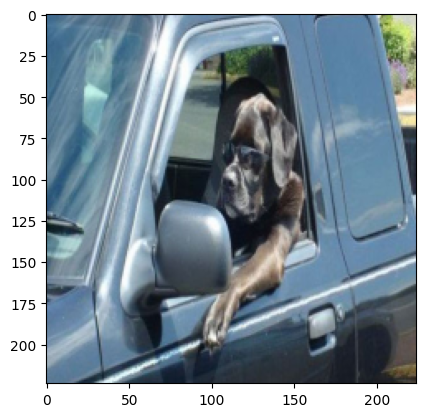

#1: p=0.853	bloodhound (163)
#2: p=0.039	washer (897)
#3: p=0.009	car_mirror (475)
#4: p=0.008	pickup (717)
#5: p=0.008	Weimaraner (178)
#6: p=0.007	Labrador_retriever (208)
#7: p=0.006	Chesapeake_Bay_retriever (209)
#8: p=0.005	limousine (627)
#9: p=0.004	pug (254)
#10: p=0.003	tub (876)


In [6]:
!wget -q https://cdn2.adrianflux.co.uk/wp-fluxposure/uploads/2014/08/no-7.jpg -O img.jpg

image = resize(plt.imread('img.jpg')[..., :3] / 255.0, (224, 224))
plt.imshow(image)
plt.show()

with torch.no_grad():
    image_tensor = torch.as_tensor(image, device=device, dtype=torch.float32)
    image_tensor = image_tensor[None].permute(0, 3, 1, 2)
    probs = torch.softmax(model(image_tensor), dim=-1)[0]

for i, class_ix in enumerate(probs.argsort(descending=True)[:10]):
    print(f"#{i + 1}: p={probs[class_ix].item():.3f}\t{class_labels[class_ix.item()]} ({class_ix.item()})")

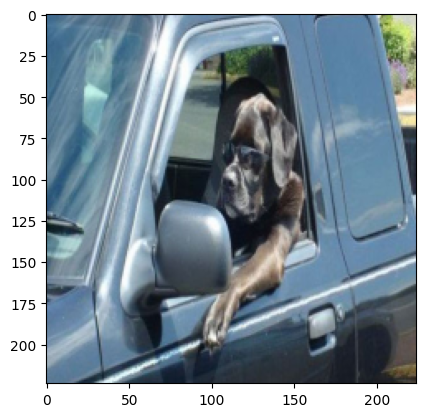

#1: p=0.305	minivan (656)
#2: p=0.195	minibus (654)
#3: p=0.098	seat_belt (785)
#4: p=0.071	limousine (627)
#5: p=0.068	jeep (609)
#6: p=0.046	recreational_vehicle (757)
#7: p=0.037	ambulance (407)
#8: p=0.032	police_van (734)
#9: p=0.024	beach_wagon (436)
#10: p=0.015	bloodhound (163)


In [7]:
!wget -q https://cdn2.adrianflux.co.uk/wp-fluxposure/uploads/2014/08/no-7.jpg -O img.jpg

image = resize(plt.imread('img.jpg')[..., :3] / 255.0, (224, 224))
plt.imshow(image)
plt.show()

with torch.no_grad():
    image_tensor = torch.as_tensor(image, device=device, dtype=torch.float32)
    image_tensor = image_tensor[None].permute(0, 3, 1, 2)
    probs = torch.softmax(model_dn(image_tensor), dim=-1)[0]

for i, class_ix in enumerate(probs.argsort(descending=True)[:10]):
    print(f"#{i + 1}: p={probs[class_ix].item():.3f}\t{class_labels[class_ix.item()]} ({class_ix.item()})")

Now let's implement SmoothGrad itself.

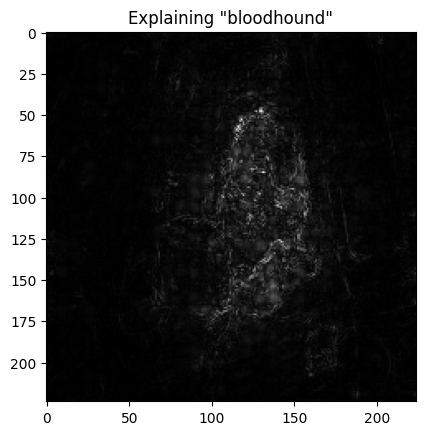

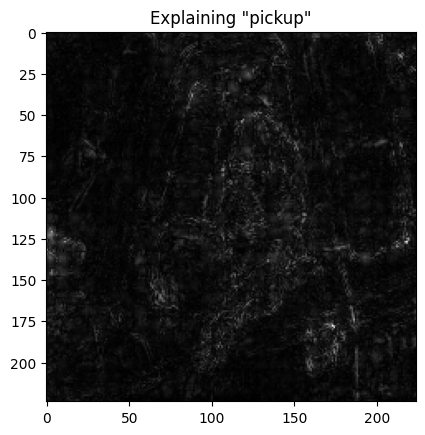

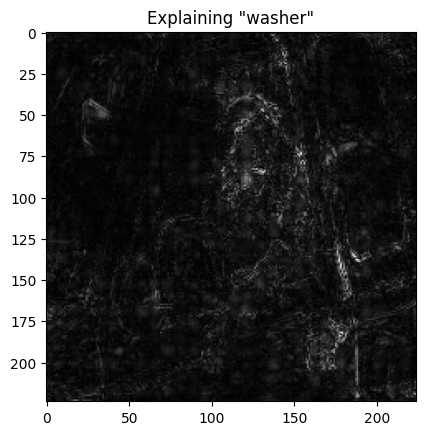

In [8]:
def explain_smoothgrad(model, image: torch.Tensor, class_ix, num_runs=32, sigma=0.1):
    image_tensor = torch.as_tensor(image, device=device, dtype=torch.float32)
    image_tensor = image_tensor[None].permute(0, 3, 1, 2)  # shape: [1, 3, h, w]

    # 1. create :num_runs: copies of an image
    # 2. apply independent random noise to each copy, use N(0, sigma) distribution
    # 3. compute gradients of logit for class_ix w.r.t. input pixels
    # 4. average these gradients across different images
    # 5. re-shape these gradients in the same shape as original image: (h, w, 3)

    image_batch = image_tensor.repeat(num_runs, 1, 1, 1)  # shape: [num_runs, 3, h, w]

    noise = torch.randn_like(image_batch) * sigma
    image_batch_with_noise = (image_batch + noise).detach().requires_grad_(True)

    logits = model(image_batch_with_noise)
    target_logits = logits[:, class_ix].sum()

    model.zero_grad()
    target_logits.backward()

    gradients = image_batch_with_noise.grad
    average_gradients = torch.mean(gradients, dim=0)
    average_gradients = average_gradients.permute(1, 2, 0)

    assert tuple(average_gradients.shape) == image.shape
    return abs(average_gradients).cpu().numpy()

for class_ix in 163, 717, 897:  # <-- insert your classes here, use numbers in (brackets)
    plt.title(f'Explaining "{class_labels[class_ix]}"')
    plt.imshow(explain_smoothgrad(model, image, class_ix, num_runs=100).mean(axis=-1), cmap='gray')
    plt.show()

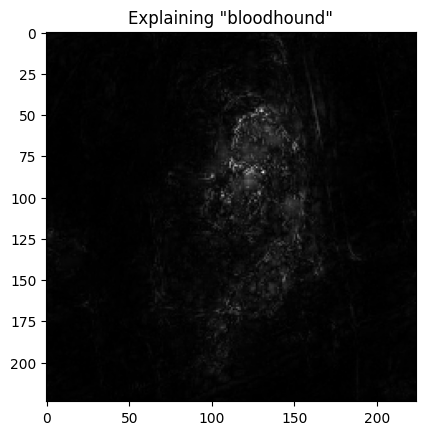

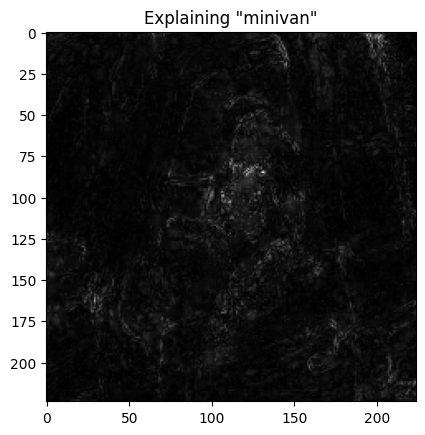

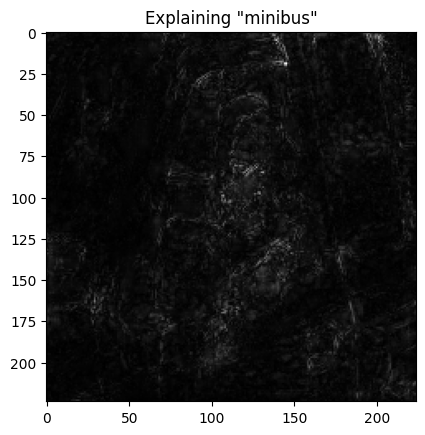

In [9]:
for class_ix in 163, 656, 654:  # <-- insert your classes here, use numbers in (brackets)
    plt.title(f'Explaining "{class_labels[class_ix]}"')
    plt.imshow(explain_smoothgrad(model_dn, image, class_ix, num_runs=100).mean(axis=-1), cmap='gray')
    plt.show()

__Let's try it out!__ Peter Higgs nobel prize photo

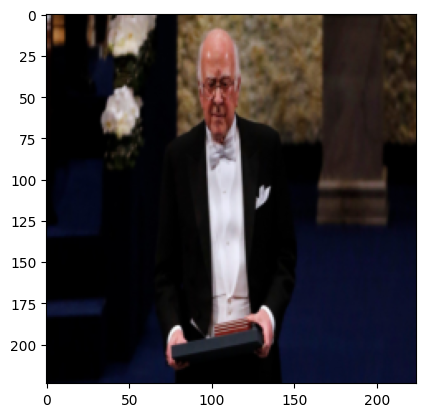

#1: p=0.211	suit (834)
#2: p=0.049	toilet_seat (861)
#3: p=0.040	plunger (731)
#4: p=0.032	vacuum (882)
#5: p=0.026	guillotine (583)
#6: p=0.024	balance_beam (416)
#7: p=0.023	academic_gown (400)
#8: p=0.022	torch (862)
#9: p=0.019	lab_coat (617)
#10: p=0.017	hook (600)


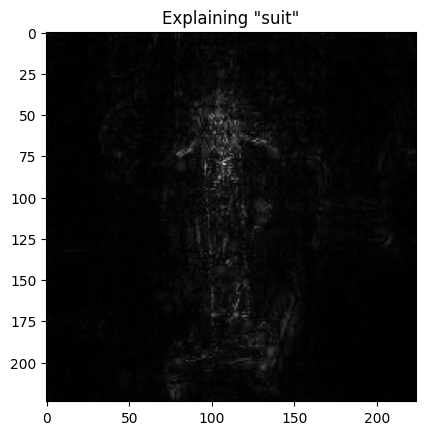

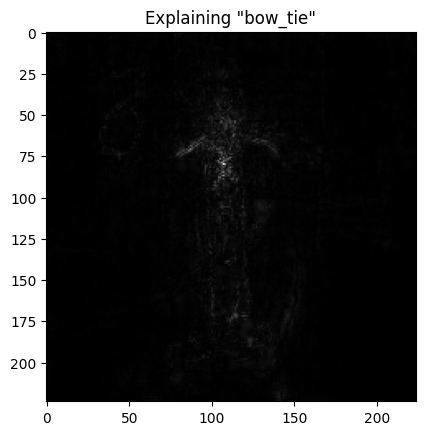

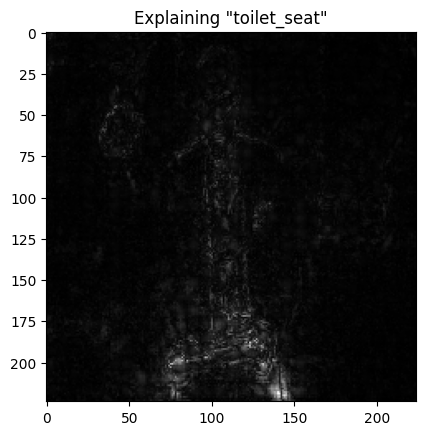

In [10]:
!wget -q https://i.pinimg.com/originals/3a/e1/83/3ae18369ab2e86be83e637ad702ec832.jpg -O img.jpg

image = resize(plt.imread('img.jpg')[..., :3] / 255.0, (224, 224))
plt.imshow(image)
plt.show()

with torch.no_grad():
    image_tensor = torch.as_tensor(image, device=device, dtype=torch.float32)
    image_tensor = image_tensor[None].permute(0, 3, 1, 2)
    probs = torch.softmax(model(image_tensor), dim=-1)[0]

for i, class_ix in enumerate(probs.argsort(descending=True)[:10]):
    print(f"#{i + 1}: p={probs[class_ix].item():.3f}\t{class_labels[class_ix.item()]} ({class_ix.item()})")

for class_ix in 834, 457, 861:
    plt.title(f'Explaining "{class_labels[class_ix]}"')
    plt.imshow(explain_smoothgrad(model, image, class_ix, num_runs=100).mean(axis=-1), cmap='gray')
    plt.show()

### SHapley Additive exPlanations
Now, let's try something heavier. The current state of the art in explaining model predictions is [SHAP](https://arxiv.org/abs/1705.07874): Shapley Additive Explanations.

This method is based on [Shapley values](https://en.wikipedia.org/wiki/Shapley_value) - a game-theoretic concept that evaluates the contribution of individual players in a cooperative game. Except this time our "players" are input features and the "game" is predicting whichever output the model gave.

Computing Shapley values naively requires $O(F!)$ time where F is the number of features. To make this computation more feasible, authors [proposed](https://arxiv.org/abs/1705.07874) several approximations, one of which relies on averaged gradients. This approximation also requires "background" data - other images similar to the ones in question that can be used as reference points.

In [11]:
import shap
# load "background" images - some 50 random images from ImageNet used as "other data points" for SHAP
background, _ = shap.datasets.imagenet50()
background = torch.as_tensor(background / 255.0, device=device, dtype=torch.float32)
background = background.permute(0, 3, 1, 2)
background.size()

torch.Size([50, 3, 224, 224])

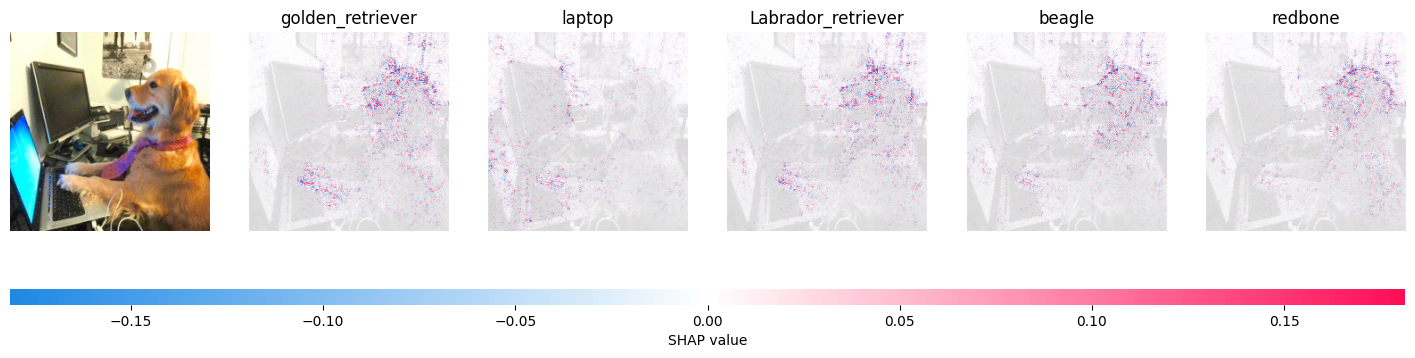

In [12]:
shap.initjs()  # run it before every (interactive) shap visualizer in colab
# v-- image to explain. If you're not using a GPU, this may take up to 20 minutes.
!wget -q https://i.pinimg.com/originals/32/da/5c/32da5c3314fcc5ebf1a7b7d1548fcb03.jpg -O img.jpg
image = resize(plt.imread('img.jpg')[..., :3] / 255.0, (224, 224))
image_tensor = torch.as_tensor(image[None], device=device, dtype=torch.float32).permute(0, 3, 1, 2)
explainer = shap.GradientExplainer((model, model.conv1), background)
shap_values, indices = explainer.shap_values(image_tensor, ranked_outputs=5, nsamples=200)
shap.image_plot(shap_values=list(np.transpose(shap_values, (4, 0, 2, 3, 1))),
                pixel_values=image_tensor.permute(0, 2, 3, 1).cpu().numpy(),
                labels=np.vectorize(lambda i: class_labels[i])(indices.cpu().numpy()))

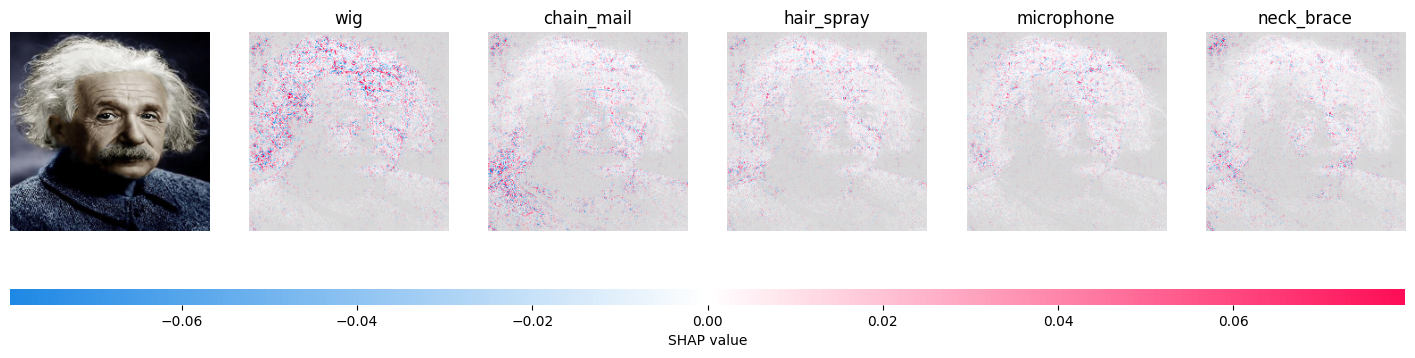

In [13]:
shap.initjs() # obligatory physicist reference
!wget -q https://images-na.ssl-images-amazon.com/images/I/51ArQaCkkZL._AC_.jpg -O img.jpg
image = resize(plt.imread('img.jpg')[..., :3] / 255.0, (224, 224))
image_tensor = torch.as_tensor(image[None], device=device, dtype=torch.float32).permute(0, 3, 1, 2)
explainer = shap.GradientExplainer((model, model.conv1), background)
shap_values, indices = explainer.shap_values(image_tensor, ranked_outputs=5, nsamples=200)
shap.image_plot(shap_values=list(np.transpose(shap_values, (4, 0, 2, 3, 1))),
                pixel_values=image_tensor.permute(0, 2, 3, 1).cpu().numpy(),
                labels=np.vectorize(lambda i: class_labels[i])(indices.cpu().numpy()))

###### Explaining classical machine learning models

Finally, let's see how SHAP explainers can be applied to more conventional machine learning models like gradient boosting.

Spoiler: exactly the same from a user's perspective. However, this time we're gonna use a different Shapley approximation implemented in TreeExplainer. For a full set of available explainers, take a look at their official [examples page](https://github.com/slundberg/shap/tree/master/notebooks).

**NB: the following cells requires JavaScript support and should work in Jupyter (not JupyterLab or cocalc)**.
In that case try running it on Google colab: https://colab.research.google.com/github/yandexdataschool/mlhep2020-assignments/blob/master/notebooks/interpretability/interpretability_demo.ipynb

In [14]:
import catboost # pip install catboost
from sklearn.datasets import fetch_california_housing
california = fetch_california_housing(as_frame=True)
X, y = california.data, california.target.values
ensemble = catboost.CatBoostRegressor(iterations=100, learning_rate=0.1)
ensemble.fit(X, y, verbose=False, plot=False)
explainer = shap.TreeExplainer(ensemble)
shap_values = explainer.shap_values(X)

shap.initjs() # visualize explanation of the first example
shap.force_plot(explainer.expected_value, shap_values[0, :], X.iloc[0, :])

In [15]:
# Explain training data: each *column* is a rotated plot from above, stacked for all training samples
shap.initjs() # (this plot is interactive, hover mouse to see feature names)
shap.force_plot(explainer.expected_value, shap_values[::100], X[::100])

### Task II: Explain Intermediate Layers of Resnet50 on ImageNet (3 points)

Sometimes, computing explanations w.r.t. pixels is more difficult (and less interpretable) than using intermediate layers that are closer to the "output" layer. The trick is to compute low-resolution explanations of output w.r.t. intermediate layer and then resizing them to fit the original image.

Each layer in deep CNN learns filters of increasing complexity. The first layers learn basic feature detection filters such as edges and corners. The middle layers learn filters that detect parts of objects — for faces, they might learn to respond to features like eyes and brows, and deeper layers capture entire objects.

**Your task** is to explain ResNet50 model outputs with respect to the convolution module from 1st, 2nd, 3rd and 4th layer of the pretrained Resnet50 network using the same GradientExplainer. *The task may require some googling or browsing the [docs](https://shap.readthedocs.io/en/latest) :)* A good starting point is from [this example](https://shap.readthedocs.io/en/latest/example_notebooks/image_examples/image_classification/Explain%20an%20Intermediate%20Layer%20of%20VGG16%20on%20ImageNet%20%28PyTorch%29.html), but for ResNet50 and on different images.

**Please use at least 10 images from across the internet (or from ImageNet) and compare the 2nd and 4th layer explanations on these images.**


In [16]:
layers = {'layer 1': model.layer1[-1].conv3,
          'layer 2': model.layer2[-1].conv3,
          'layer 3': model.layer3[-1].conv3,
          'layer 4': model.layer4[-1].conv3}

model.eval()

ResNet(
  (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
  (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (relu): ReLU(inplace=True)
  (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
  (layer1): Sequential(
    (0): Bottleneck(
      (conv1): Conv2d(64, 64, kernel_size=(1, 1), stride=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (conv3): Conv2d(64, 256, kernel_size=(1, 1), stride=(1, 1), bias=False)
      (bn3): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (downsample): Sequential(
        (0): Conv2d(64, 256, kernel_size=(1, 1), stride=(1, 

In [17]:
def explain_intermediate_layer(img, layer, background, nsamples=100):
    explainer = shap.GradientExplainer((model, layer), background)
    shap_values, _ = explainer.shap_values(img, ranked_outputs=1, nsamples=nsamples)
    values = shap_values[0, :, :, :, 0]

    heatmap = np.abs(values).mean(axis=0)

    h, w = img.shape[-2:]
    heatmap = resize(heatmap, (h, w), preserve_range=True)
    heatmap = (heatmap - heatmap.min()) / (heatmap.max() - heatmap.min() + 1e-8)

    return heatmap

In [18]:
images_cnt = 10

all_idxs = np.arange(len(background))
image_idxs = np.linspace(0, len(background) - 1, images_cnt, dtype=int)
bg_idxs = np.setdiff1d(all_idxs, image_idxs)

images = background[image_idxs].clone()           # images to explain
explain_background = background[bg_idxs].clone()  # background for SHAP

print(f'Images: {images.shape}, background: {explain_background.shape}')

Images: torch.Size([10, 3, 224, 224]), background: torch.Size([40, 3, 224, 224])


Let's generate explanations for 4 layers:

In [19]:
all_explanations = {}
for i in range(images_cnt):
    cur_img = images[i:i+1]

    with torch.no_grad():
        logits = model(cur_img)
        class_ix = logits.argmax(dim=1).item()

    class_name = class_labels[class_ix]
    print(f'Image {i + 1}/{images_cnt}: {class_name}')

    explanations = {}
    for layer_name, layer in layers.items():
        heatmap = explain_intermediate_layer(cur_img, layer, explain_background, nsamples=100)
        explanations[layer_name] = heatmap

    all_explanations[i] = {'image': cur_img,
                           'class': class_name,
                           'explanations': explanations}

Image 1/10: window_screen
Image 2/10: dishwasher
Image 3/10: spider_web
Image 4/10: dining_table
Image 5/10: cheeseburger
Image 6/10: paper_towel
Image 7/10: tray
Image 8/10: suit
Image 9/10: bonnet
Image 10/10: warplane


Let's look at the shap explanation for 1 image:

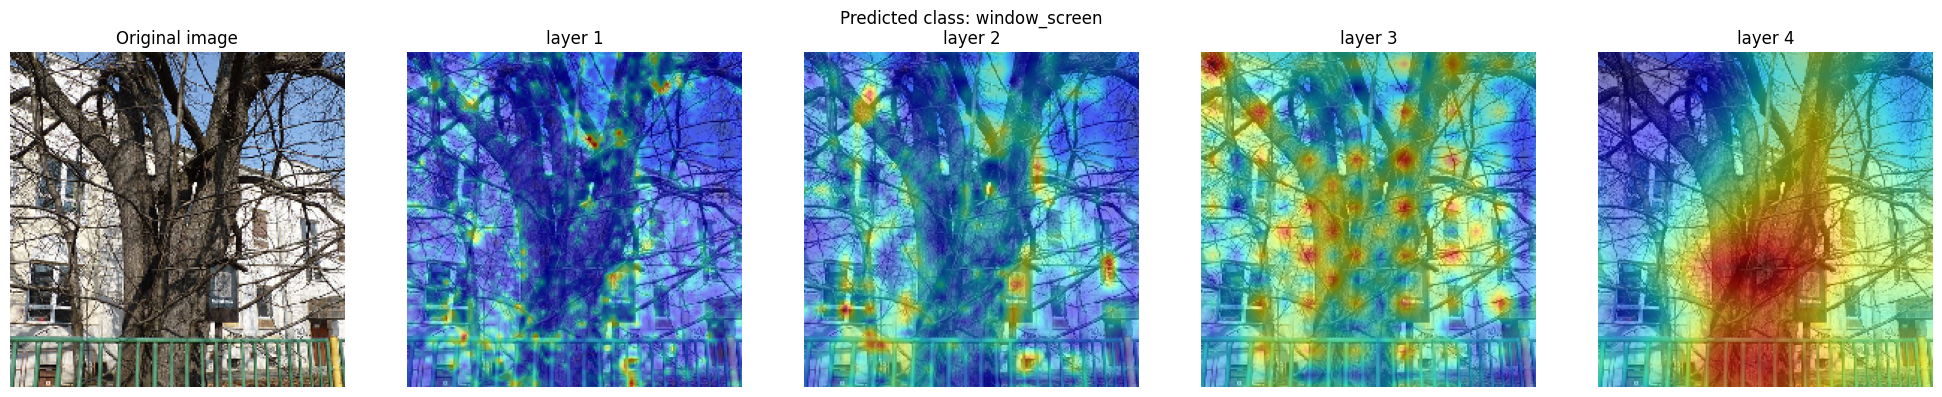

In [20]:
explanation_example = all_explanations[0]
image = explanation_example['image'][0].permute(1, 2, 0).cpu().numpy()

fig, axes = plt.subplots(1, 5, figsize=(20, 4))

axes[0].imshow(image)
axes[0].set_title('Original image')
axes[0].axis('off')

for j, (layer_name, heatmap) in enumerate(explanation_example['explanations'].items()):
    axes[j+1].imshow(image)
    axes[j+1].imshow(heatmap, cmap='jet', alpha=0.5)
    axes[j+1].set_title(layer_name)
    axes[j+1].axis('off')

plt.suptitle(f'Predicted class: {explanation_example['class']}', fontsize=12)

plt.tight_layout()
plt.show()

Comparing layer2 and layer4 on all 10 images:

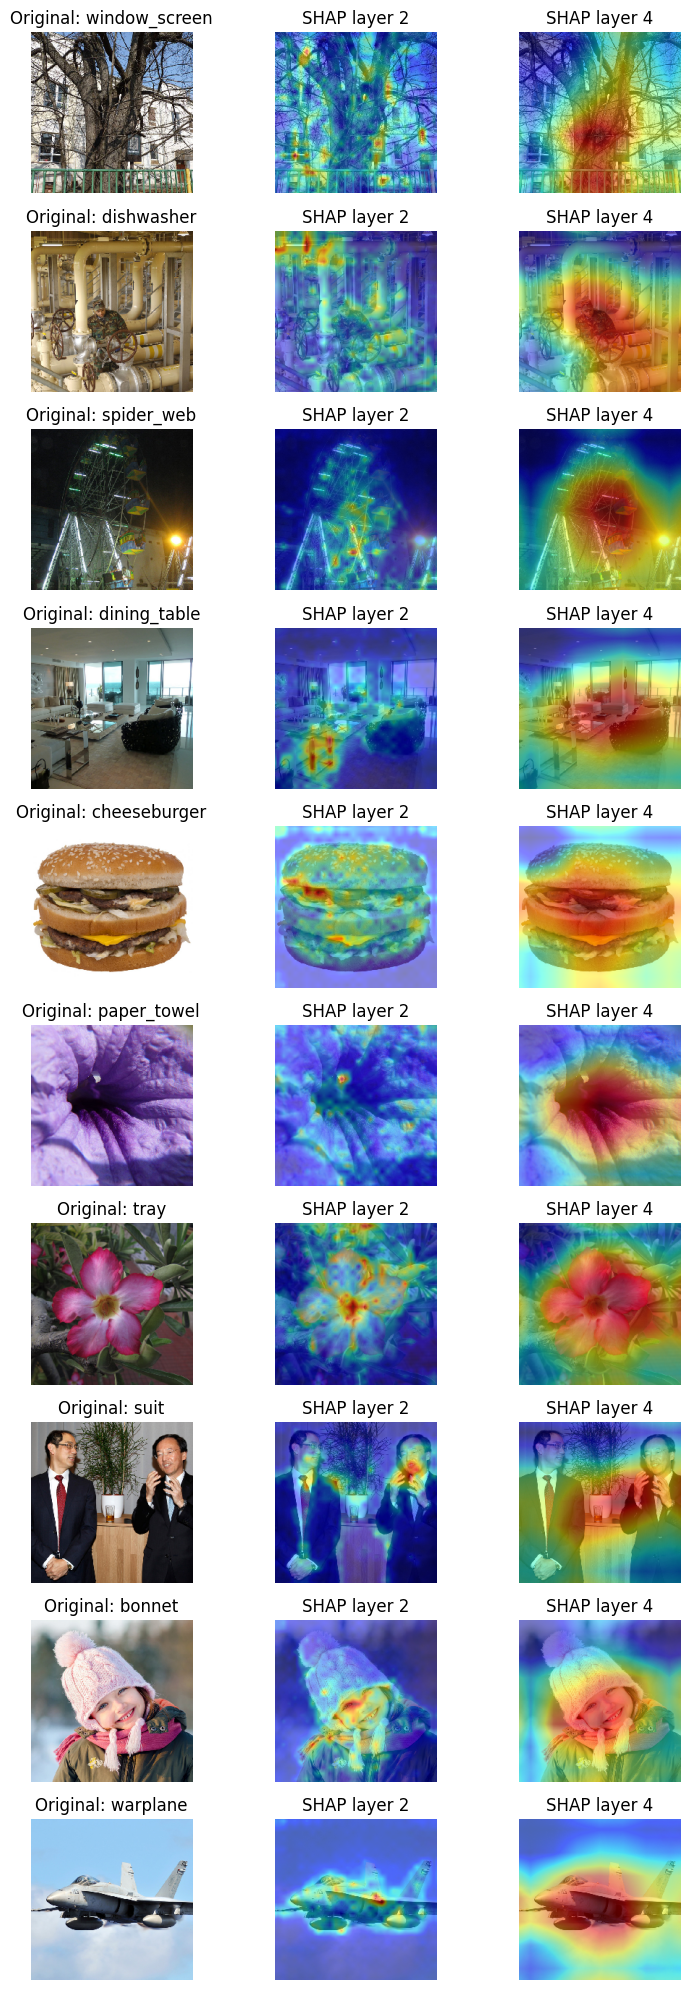

In [21]:
fig, axes = plt.subplots(images_cnt, 3, figsize=(8, 2 * images_cnt))

for i in range(images_cnt):
    res = all_explanations[i]
    image = res['image'][0].permute(1, 2, 0).cpu().numpy()

    heatmap2 = res['explanations']['layer 2']
    heatmap4 = res['explanations']['layer 4']

    axes[i, 0].imshow(image)
    axes[i, 0].set_title(f'Original: {res["class"]}')

    axes[i, 1].imshow(image)
    axes[i, 1].imshow(heatmap2, cmap='jet', alpha=0.5, vmin=0, vmax=1)
    axes[i, 1].set_title('SHAP layer 2')

    axes[i, 2].imshow(image)
    axes[i, 2].imshow(heatmap4, cmap='jet', alpha=0.5, vmin=0, vmax=1)
    axes[i, 2].set_title('SHAP layer 4')

    for ax in axes[i]:
        ax.axis('off')

plt.tight_layout()
plt.show()

**Conclusion:** Layer 2 produces more detailed and localized heatmaps, it highlights smaller regions of the images. Layer 4 emphasizes larger regions, often associated with the predicted class.

## References

* SHAP explainer based on superpixels - [notebook](https://slundberg.github.io/shap/notebooks/ImageNet%20VGG16%20Model%20with%20Keras.html)
* SHAP reference notebook - [view on github](https://github.com/slundberg/shap/tree/master/notebooks)
* More various explainers in [ELI5](https://github.com/TeamHG-Memex/eli5)
* Same notebook on Google [Colab](https://colab.research.google.com/github/yandexdataschool/mlhep2020-assignments/blob/master/notebooks/interpretability/interpretability_demo.ipynb)